# Uczenie maszynowe i sieci neuronowe

### Ćwiczenia 1.

---

## Regresja liniowa

Ćwiczenia te poświęcone są zagadnieniu regresji liniowej. Zaimplementujemy metodę gradientu prostego w celu rozwiązania problemu regresji liniowej, przy okazji ćwicząc stosowanie biblioteki NumPy.

---

In [46]:
import numpy as np
from matplotlib import pyplot as plt
import testing

[Moduł `testing`](testing.py) zawiera przygotowane na potrzeby tych ćwiczeń narzędzia do testowania poprawności kodu źródłowego.

---

### Regresja liniowa i metoda gradientu prostego

**Regresja liniowa** to metoda statystyczna służąca do znajdowania zależności między zmiennymi, w której przewidywaną wartość $\hat{Y}$ zmiennej zależnej $Y$ opisujemy liniową funkcją zmiennej niezależnej $X$:
$$
\hat{Y} = w X + b ,
$$
gdzie $w$ i $b$ są stałymi parametrami: $w$ to współczynnik kierunkowy, zaś $b$ – wyraz wolny. Obserwowane wartości $Y$ mogą różnić się od przewidywań $\hat{Y}$, np. wskutek szumu. Metodę tę można uogólnić na przypadek wielu zmiennych niezależnych, my jednak skupimy się na sytuacji, w której mamy do czynienia tylko z jedną zmienną niezależną.

Rozważmy zestaw danych $\, \left( X^{(k)}, \, Y^{(k)} \right)$, $\, k = 1, \, 2, \, \ldots , \, N . \, $ **Funkcja kosztu** dla tych danych to
$$
L ( \hat{Y} , \, Y ) = \sum_{k=1}^{N} \left(\hat{Y}^{(k)} - Y^{(k)} \right) ^2 = \sum_{k=1}^{N}\left(Y^{(k)} -w X^{(k)} -b\right) ^2 .
$$
Jest to najczęściej stosowana postać funkcji kosztu (oparta na znanej ze statystyki metodzie najmniejszych kwadratów), istnieją też jednak inne jej postacie.

Gdy wstawimy do funkcji kosztu konkretne dane $\, \left( X^{(k)}, \, Y^{(k)} \right) , \,$ możemy na nią patrzeć już nie jako na funkcję danych, $L ( \hat{Y} , \, Y )$, lecz jako na funkcję parametrów $w$ i $b$ – będziemy ją w tym kontekście oznaczać $\chi ( w , \, b )$. Zagadnienie **regresji liniowej jednej zmiennej** polega na wyznaczeniu takich wartości $w$ i $b$, by funkcja kosztu $\chi ( w , \, b )$ osiągała minimum.

W celu wyznaczenia punktów stacjonarnych funkcji $\chi ( w , \, b )$, czyli punktów, w których funkcja ta może mieć minimum, musimy najpierw obliczyć jej pochodne cząstkowe:
$$
\begin{align*}
\frac{\partial \chi(w, \, b)}{\partial w} &=  -2   \sum_{k=1}^{N}\left(Y^{(k)} -w X^{(k)} -b\right)X^{(k)}, \\[3pt]
\frac{\partial \chi(w, \, b)}{\partial b} &=  -2   \sum_{k=1}^{N}\left(Y^{(k)} -w X^{(k)} -b\right),
\end{align*}
$$
a następnie wyznaczyć miejsca zerowe tych pochodnych. Wektor $\nabla \chi(w, \, b)$ zbudowany z pochodnych cząstkowych funkcji $\chi ( w , \, b )$,
$$
\nabla \chi(w, \, b) = \begin{bmatrix}
\displaystyle \frac{\partial \chi ( w , \, b )}{\partial w} \\[12pt]
\displaystyle \frac{\partial \chi ( w , \, b )}{\partial b}
\end{bmatrix} ,
$$
nazywać będziemy **gradientem** funkcji $\chi ( w , \, b )$.

Problem znalezienia minimum funkcji $\chi ( w , \, b )$ da się wprawdzie rozwiązać analitycznie, my posłużymy się jednak odpowiednią metodą numeryczną, określaną jako **metoda gradientu prostego** (ang. *gradient descent*). Jest to metoda iteracyjna – oznacza to, że nie da nam ona wprost optymalnych wartości $w$ i $b$, których szukamy, lecz przy odpowiednio małym dodatnim współczynniku uczenia pozwoli otrzymywać coraz lepsze ich przybliżenia, gdy będziemy powtarzać krok iteracyjny. Zbyt duży współczynnik uczenia może prowadzić do rozbieżności.

**Algorytm rozwiązania zagadnienia regresji liniowej metodą gradientu prostego**.

1. „Zgadujemy” wartości początkowe: $w_0$ i $b_0$. Wartość $w_0$ będziemy losować z rozkładu normalnego Gaussa, a $b_0$ przyjmiemy równe zeru lub również wylosujemy, zależnie od parametru `bias`.
2. Krok iteracyjny: w pętli dla $m = 0 , \, 1 , \,  \ldots , \, M-1$ (liczbę iteracji $M$ ustalimy z góry) wykonujemy następujące czynności:
   * *propagacja w przód*: obliczamy przewidywania $\hat{Y}^{(k)} = w_m X^{(k)} + b_m$ oraz funkcję kosztu $\chi ( w_m , \, b_m )$,
   * *obliczenie gradientu*: obliczamy obie pochodne cząstkowe funkcji kosztu (w sieciach neuronowych służy do tego propagacja wsteczna),
   * *aktualizacja parametrów*: obliczamy kolejne przybliżenie optymalnych wartości $w$ i $b$ za pomocą wzorów:
     $$
     \begin{align*}
     w_{m+1} &= w_m - \alpha \frac{\partial \chi ( w_m , \, b_m )}{\partial w}, \\[3pt]
     b_{m+1} &= b_m - \alpha \frac{\partial \chi ( w_m , \, b_m )}{\partial b},
     \end{align*}
     $$
     gdzie $\alpha $ jest hiperparametrem nazywanym **współczynnikiem uczenia** (ang. *learning rate*); będziemy zakładać, że parametr ten jest stały, choć można rozszerzyć metodę gradientu prostego na przypadek zmiennego, optymalnie dobieranego współczynnika uczenia.

---

### Zadanie 1. Funkcja kosztu.

Korzystając z podanego wyżej wzoru, napisz funkcję `cost` obliczającą wartość funkcji kosztu dla danych wartości $w$ i $b$ oraz określonego zestawu danych.

Funkcja `cost` powinna sprawdzać, czy długości ciągów danych $X$ i $Y$ są równe i wynoszą co najmniej 2, i zwrócić `None`, jeśli któryś z tych warunków nie jest spełniony. W tych ćwiczeniach przyjmujemy, że dane są jednowymiarowymi tablicami NumPy.

_Wskazówka._ Mogą Ci się przydać funkcje [dot](https://numpy.org/doc/stable/reference/generated/numpy.dot.html) i [sum](https://numpy.org/doc/stable/reference/generated/numpy.sum.html) z biblioteki NumPy.

In [47]:
def cost(w, b, data):
    """
    Funkcja kosztu danych dla parametrów w, b.
    
    :param w: float, parametr w.
    :param b: float, parametr b.
    :param data: Słownik z danymi, data["xi"] i data["yi"] to jednowymiarowe tablice NumPy.

    :return: Jeśli długość danych jest większa lub równa 2 oraz długości data["xi"] i data["yi"] są równe, wynikiem jest wartość funkcji kosztu dla parametrów w i b (liczba typu float). W przeciwnym przypadku wynikiem jest None.    
    """

    xi = data["xi"] 
    yi = data["yi"] 

    if (len(xi) >= 2 and len(yi) >=2) and (len(xi) == len(yi)):
        y_pred = w * xi + b
        error = yi - y_pred
        squared_error = error ** 2

        return(squared_error.sum())
        

    else:
        return(None)

  



Wykonaj poniższą komórkę, aby sprawdzić, czy Twój kod działa poprawnie.

In [48]:
try:
    assert(cost(1, 1, testing.datawrong) is None)
    assert(cost(1, 1, testing.datamismatch) is None)
    assert(cost(1, 1, testing.dataempty) is None)
    assert(abs(cost(0, 0, testing.data0)) < testing.eps_test)
    assert(abs(cost(0, 1, testing.data0) - 2) < testing.eps_test)
    assert(abs(cost(0, 0, testing.data1) - 13) < testing.eps_test)
    assert(abs(cost(1, 1, testing.data1)) < testing.eps_test)
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Gratulacje, Twój kod działa poprawnie! :)


---

### Zadanie 2. Gradient.

Korzystając z podanego wyżej wzoru, napisz funkcję `grad` obliczającą gradient funkcji kosztu dla danych wartości $w$ i $b$ oraz określonego zestawu danych.

Funkcja `grad` powinna sprawdzać, czy długości ciągów danych $X$ i $Y$ są równe i wynoszą co najmniej 2, i zwrócić `None`, jeśli któryś z tych warunków nie jest spełniony. W tych ćwiczeniach przyjmujemy, że dane są jednowymiarowymi tablicami NumPy.

_Wskazówka._ Mogą Ci się przydać funkcje [dot](https://numpy.org/doc/stable/reference/generated/numpy.dot.html) i [sum](https://numpy.org/doc/stable/reference/generated/numpy.sum.html) z biblioteki NumPy.

In [49]:
def grad(w, b, data):
    """
    Gradient funkcji kosztu.
    
    :param w: float, parametr w.
    :param b: float, parametr b.
    :param data: Słownik z danymi, data["xi"] i data["yi"] to jednowymiarowe tablice NumPy.

    :return: Jeśli długość danych jest większa lub równa 2 oraz długości data["xi"] i data["yi"] są równe, wynikiem ma być słownik postaci {"dw": pochodna po w, "db": pochodna po b}. W przeciwnym przypadku wynikiem jest None.    
    """
    
    xi = data["xi"]
    yi = data["yi"]

    if len(xi) == len(yi) and len(xi) >= 2 and len(yi) >= 2:
        y_pred = w * xi + b
        error = yi - y_pred

        dw = -2 * (xi * error).sum()
        db = -2 * error.sum()
        return({"dw":dw,"db":db})
    
    else:

     return(None)
     

Wykonaj poniższą komórkę, aby sprawdzić, czy Twój kod działa poprawnie.

In [50]:
try:
    assert(grad(1, 1, testing.datawrong) is None)
    assert(grad(1, 1, testing.datamismatch) is None)
    assert(grad(1, 1, testing.dataempty) is None)
    assert(abs(grad(0, 0, testing.data0)["dw"]) < testing.eps_test)
    assert(abs(grad(0, 0, testing.data0)["db"]) < testing.eps_test)
    np.testing.assert_allclose([grad(1, 1, testing.data0)[key] for key in ("dw", "db")], [0, 4], rtol=0, atol=testing.eps_test)
    np.testing.assert_allclose([grad(0, 0, testing.data1)[key] for key in ("dw", "db")], [-16, -10], rtol=0, atol=testing.eps_test)
    assert(set(grad(1, 1, testing.data1).keys()) == {"dw", "db"})
    for key in grad(1, 1, testing.data1).keys():
        assert(abs(grad(1, 1, testing.data1)[key]) < testing.eps_test)
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Gratulacje, Twój kod działa poprawnie! :)


---

### Zadanie 3. Wartości początkowe.

Napisz funkcję `initialization` zwracającą początkowe wartości parametrów $w$ i $b$ zgodnie z podanym wyżej algorytmem rozwiązania zagadnienia regresji liniowej metodą gradientu prostego. Wartości te powinny być losowane z rozkładu normalnego Gaussa o parametrach zadanych jako argumenty funkcji, z wyjątkiem $b_0 = 0$ dla `bias=False`.

_Wskazówka._ Może Ci się przydać metoda [normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal.html) klasy `Generator` z modułu `random` biblioteki NumPy.

In [51]:
def initialization(mu1, sigma1, mu2, sigma2, bias=False):
    """
    Funkcja inicjalizująca parametry w i b z rozkładu normalnego Gaussa.
    
    :param mu1: float, średnia rozkładu normalnego, z którego losujemy w.
    :param sigma1: float, odchylenie standardowe rozkładu normalnego, z którego losujemy w.
    :param mu2: float, średnia rozkładu normalnego, z którego losujemy b.
    :param sigma2: float, odchylenie standardowe rozkładu normalnego, z którego losujemy b.
    :param bias: bool, jeśli False (domyślnie), to początkowe b = 0; jeśli True, to losujemy początkowe b. W obu przypadkach b podlega później uczeniu.

    :return: float w, float b
    """

    w = np.random.normal(mu1, sigma1)
    
    if bias:
     b = np.random.normal(mu2,sigma2)
    else:
     b = 0

    return w, b
    ### Koniec miejsca na Twój kod #####################################

Wykonaj poniższą komórkę, aby sprawdzić, czy Twój kod działa poprawnie.

In [52]:
try:
    assert(len(initialization(0, 1, 0, 1)) == 2)
    mu1 = -1
    mu2 = 1
    sigma1 = 0.5
    sigma2 = 2
    lst1 = [initialization(mu1, sigma1, mu2, sigma2, True)[0] for _ in range(1000)]
    lst2 = [initialization(0, 1, mu2, sigma2, True)[1] for _ in range(1000)]
    lst3 = np.array([initialization(0, 1, mu2, sigma2, False)[1] for _ in range(1000)])
    # Przybliżony test: tolerancja uwzględnia wahania losowe dla 1000 próbek.
    assert(testing.sigma_check(lst1, mu1, sigma1) < 0.06)
    assert(testing.sigma_check(lst2, mu2, sigma2) < 0.06)
    assert(np.all(lst3 == 0))
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Gratulacje, Twój kod działa poprawnie! :)


---

### Zadanie 4. Funkcja kosztu i gradient.

Napisz funkcję `cost_and_grad` obliczającą funkcję kosztu i jej gradient, zgodnie z podanym wyżej opisem algorytmu rozwiązania zagadnienia regresji liniowej metodą gradientu prostego.

Wykorzystaj napisane w poprzednich zadaniach funkcje `cost` i `grad`.

In [53]:
def cost_and_grad(w, b, data):
    """
    Obliczenie funkcji kosztu i jej gradientu.
    
    :param w: float, parametr w.
    :param b: float, parametr b.
    :param data: Słownik z danymi, data["xi"] i data["yi"] to jednowymiarowe tablice NumPy.
    
    :return: grad(w, b, data), cost(w, b, data)
    
    """
    
    return [grad(w,b,data),cost(w,b,data)]
    ### Koniec miejsca na Twój kod #####################################

Wykonaj poniższą komórkę, aby sprawdzić, czy Twój kod działa poprawnie.

In [54]:
try:
    assert(cost_and_grad(1, 1, testing.data0)[0] == grad(1, 1, testing.data0))
    assert(cost_and_grad(1, 1, testing.data0)[1] == cost(1, 1, testing.data0))
    assert(cost_and_grad(2, 2, testing.data0)[0] == grad(2, 2, testing.data0))
    assert(cost_and_grad(2, 2, testing.data0)[1] == cost(2, 2, testing.data0))
    assert(cost_and_grad(1, 1, testing.data1)[0] == grad(1, 1, testing.data1))
    assert(cost_and_grad(1, 1, testing.data1)[1] == cost(1, 1, testing.data1))
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Gratulacje, Twój kod działa poprawnie! :)


---

### Zadanie 5. Aktualizacja parametrów.

Napisz funkcję `gradient_step` aktualizującą parametry w i b, zgodnie z podanym wyżej opisem algorytmu rozwiązania zagadnienia regresji liniowej metodą gradientu prostego.

In [55]:
def gradient_step(w, b, grad, alpha):
    """
    Aktualizacja parametrów metodą gradientu prostego.
        
    :param w: float, parametr w.
    :param b: float, parametr b.
    :param grad: Słownik, {"dw": pochodna po w, "db": pochodna po b}.
    :param alpha: float, współczynnik uczenia.
    
    :return: float w, float b
    """

    ### Miejsce na Twój kod ############################################
    w = w - alpha*grad["dw"]
    b = b - alpha*grad["db"]
    
    return w, b
    ### Koniec miejsca na Twój kod #####################################

Wykonaj poniższą komórkę, aby sprawdzić, czy Twój kod działa poprawnie.

In [56]:
try:
    assert(gradient_step(1, 1, {"dw": 1, "db": 1}, 0)==(1, 1))
    assert(gradient_step(1, 1, {"dw": 0, "db": 0}, 1)==(1, 1))
    np.testing.assert_allclose(gradient_step(1, 1, {"dw": 1, "db": 1}, 0.01), (0.99, 0.99), rtol=0, atol=testing.eps_test)
    np.testing.assert_allclose(gradient_step(1, 2, {"dw": 1, "db": 0}, 0.01), (0.99, 2), rtol=0, atol=testing.eps_test)
    np.testing.assert_allclose(gradient_step(0.5, 2, {"dw": 0, "db": 1}, 0.01), (0.5, 1.99), rtol=0, atol=testing.eps_test)
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Gratulacje, Twój kod działa poprawnie! :)


---

### Zadanie 6. Regresja liniowa.

Napisz funkcję `optimize` implementującą algorytm rozwiązania zagadnienia regresji liniowej metodą gradientu prostego.

Wykorzystaj funkcje napisane w poprzednich zadaniach.

In [57]:
def optimize(
        data,
        alpha = 0.005,
        niter = 100,
        mu1 = 1,
        sigma1 = 0.1,
        mu2 = 1,
        sigma2 = 0.1,
        bias = False,
        print_cost = False
    ):
    """
    Implementacja algorytmu rozwiązania zagadnienia regresji liniowej metodą gradientu prostego.
    
    :param data: Słownik z danymi, data["xi"] i data["yi"] to jednowymiarowe tablice NumPy.
    :param alpha: float, dodatni współczynnik uczenia, który należy dobrać do danych.
    :param niter: int, liczba iteracji.
    :param mu1: float, średnia rozkładu normalnego, z którego losujemy w.
    :param sigma1: float, odchylenie standardowe rozkładu normalnego, z którego losujemy w.
    :param mu2: float, średnia rozkładu normalnego, z którego losujemy b.
    :param sigma2: float, odchylenie standardowe rozkładu normalnego, z którego losujemy b.
    :param bias: bool, jeśli False (domyślnie), to początkowe b = 0; jeśli True, to losujemy początkowe b. W obu przypadkach b podlega później uczeniu.
    :param print_cost: bool, jeśli True, funkcja przed aktualizacją dla iteracji 0, 50, 100, ... wypisuje na ekranie krotkę (numer iteracji, wartość w, wartość b, koszt).

    :return: float w, float b, float koszt obliczony dla zwracanych wartości w i b.
    """

    ### Miejsce na Twój kod ############################################
    w, b = initialization(mu1, sigma1, mu2,sigma2,bias)


    for i in range(niter):
        gradient, current_cost = cost_and_grad(w,b,data) # Oblicz gradient i koszt funkcją cost_and_grad.

        print(f"Iteracja {i}, w: {w}, b:{b}, koszt przed aktualizacją:{current_cost}") # Opcjonalnie wypisz numer iteracji, w, b i current_cost przed aktualizacją.
        grad_w,grad_b=gradient
        w, b = gradient_step(w,b,gradient,alpha) # Zaktualizuj parametry funkcją gradient_step.
        
    return w, b, cost(w, b, data)
    ### Koniec miejsca na Twój kod #####################################

In [58]:
try:
    xarray = np.array([0, 1, 2, 3, 4, 5, 6])
    yarray = np.array([1., 1.5, 2., 2.5, 3., 3.5, 4.])
    data = {"xi": xarray, "yi": yarray}
    
    opt = optimize(data, 0.005, 1000)
    eps = 0.0001
    eps2 = 0.001
    print(opt[2])
    
    assert(abs(opt[0] - 0.5) < eps)
    assert(abs(opt[1] - 1.0) < eps2)
    assert(abs(opt[2]) < eps2)
    # Jeden krok z ustalonego punktu sprawdza też zgodność kosztu z końcowymi parametrami.
    np.testing.assert_allclose(optimize(data, 0.005, 1, mu1=1, sigma1=0),
                               (0.755, -0.035, 2.331), rtol=0, atol=testing.eps_test)
    print("Gratulacje, Twój kod działa poprawnie! :)")
except AssertionError:
    print("Twój kod nie działa poprawnie, spróbuj ponownie. :(")

Iteracja 0, w: 0.9715344824964051, b:0, koszt przed aktualizacją:7.428925639817867
Iteracja 1, w: 0.7524381034246765, b:-0.029022241324245066, koszt przed aktualizacją:2.301076288267256
Iteracja 2, w: 0.7388140999863123, b:-0.010002686150729984, koszt przed aktualizacją:2.2001447842511497
Iteracja 3, w: 0.7335938330904214, b:0.010546540882695531, koszt przed aktualizacją:2.1111707108299953
Iteracja 4, w: 0.7288086713927718, b:0.030753578071918353, koszt przed aktualizacją:2.02580710820492
Iteracja 5, w: 0.7241345290302467, b:0.050551006614402, koszt przed aktualizacją:1.9438951389446741
Iteracja 6, w: 0.7195563962236978, b:0.06994418505504206, koszt przed aktualizacją:1.8652952178788182
Iteracja 7, w: 0.715071796798574, b:0.08894124889421258, koszt przed aktualizacją:1.7898734248240329
Iteracja 8, w: 0.710678799444087, b:0.10755028414391715, koszt przed aktualizacją:1.7175012545919914
Iteracja 9, w: 0.7063755322797453, b:0.1257792163705847, koszt przed aktualizacją:1.6480553980039503
I

Przyjrzymy się teraz wynikom naszego algorytmu. Ponieważ funkcja kosztu jest sumą kwadratów błędów, zwiększenie liczby punktów i skali wartości $X$ może wymagać odpowiedniego zmniejszenia współczynnika uczenia. Dla poniższych danych wybieramy $\alpha = 0.00002$.

In [59]:
rng = np.random.default_rng()

sigma = 0.1
xarray = np.linspace(0, 10, 1000)
yarray = 0.5 * xarray + 1 + np.array([rng.normal(0, sigma) for _ in range(0, len(xarray), 1)])
data_new = {"xi": xarray, "yi": yarray}

opt = optimize(data_new, 0.00002, 1000)

Iteracja 0, w: 1.0032480523285268, b:0, koszt przed aktualizacją:4423.626075196302
Iteracja 1, w: 0.5319367332644465, b:-0.06064626492692295, koszt przed aktualizacją:830.7049039945852
Iteracja 2, w: 0.7014842813393021, b:-0.024604415443952914, koszt przed aktualizacją:349.53464674710654
Iteracja 3, w: 0.6376469172408626, b:-0.023913749555272798, koszt przed aktualizacją:281.2182071217043
Iteracja 4, w: 0.6588305062728489, b:-0.010483237482452014, koszt przed aktualizacją:267.75313002109453
Iteracja 5, w: 0.6490690709850722, b:-0.0018266636989412999, koszt przed aktualizacją:261.64974299465337
Iteracja 6, w: 0.6505980821286251, b:0.008435934190784334, koszt przed aktualizacją:256.6070088221113
Iteracja 7, w: 0.6480348718083722, b:0.017982225936210343, koszt przed aktualizacją:251.78747349317234
Iteracja 8, w: 0.646981727416769, b:0.027659308075869915, koszt przed aktualizacją:247.07844311242886
Iteracja 9, w: 0.6453980619184315, b:0.03715993580826374, koszt przed aktualizacją:242.46339

Naniesiemy dane i dopasowaną funkcję na wykres.

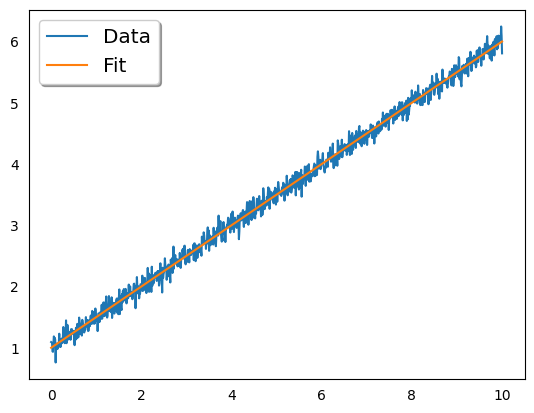

In [60]:
y = lambda x: opt[0]*x + opt[1]

fig, ax = plt.subplots()
ax.plot(xarray, yarray, label='Data')
ax.plot(xarray, y(xarray), label='Fit')
legend = ax.legend(loc='upper left', shadow=True, fontsize='x-large')

plt.tick_params(
    axis="both",
    which="both",
    bottom=False,
    top=False,
    labelbottom=True,
    left=False,
    right=False,
    labelleft=True
)

Możesz teraz pobawić się zaimplementowanym algorytmem. Wykonaj wykresy (takie, jak ten powyżej, oraz na przykład wykresy funkcji kosztu) dla różnych wartości współczynnika uczenia $\alpha $ i liczby iteracji i dobierz je tak, by otrzymać jak najlepsze dopasowanie do ustalonych danych. Osobno zbadaj wpływ odchylenia standardowego szumu $\sigma $ na dane i wyniki dopasowania; zmiana $\sigma $ zmienia sam zbiór danych.

---

### Zadanie dodatkowe. Regresja kwadratowa. 

Wzorując się na omówionym powyżej rozwiązaniu zagadnienia regresji liniowej, zaimplementuj rozwiązanie problemu regresji kwadratowej, opartej na zależności
$$
\hat{Y} = a X^2 + b X + c .
$$